# **Phase 3**

# **1-Problem**

The global financial industry faces significant challenges in accurately assessing credit risk, as loan defaults lead to substantial financial losses each year. Traditional evaluation methods often struggle to capture the complex, non-linear relationships within a borrower's financial and personal history. This limitation in early detection results in suboptimal lending decisions, increasing the severity of financial exposure and elevating default rates. Therefore, there is a critical need to enhance credit risk prediction strategies and identify high-risk loan applicants at earlier stages, as this plays a vital role in reducing financial losses and improving decision-making at both the individual and institutional levels.

# **2-Data Mining Task**

This study applies two essential data mining approaches, classification and clustering, to evaluate credit risk. The classification technique builds a predictive model to determine whether a loan applicant is likely to default based on financial and personal attributes such as age, credit amount, loan duration, and account status. The model classifies applicants into two categories: good credit risk or bad credit risk. Clustering is used to group applicants based on similarities in their financial characteristics without using the predefined risk label. This unsupervised approach reveals hidden patterns, applicant subgroups, and underlying financial behaviors. Combining both methods provides a deeper understanding of applicant profiles and enhances the identification of risk factors associated with credit default.

# **3-Data**

The dataset used in this project was obtained from Kaggle (originally from the UCI Machine Learning Repository) and contains financial and personal information for 1,000 loan applicants across 11 attributes. These include demographic factors (Age, Sex), financial measurements (Credit amount, Duration), and categorical indicators (Job, Housing, Saving accounts, Checking account, Purpose). The target variable, Risk, is binary with 700 positive cases (good risk) and 300 negative cases (bad risk), making it highly suitable for predictive modeling.
Phase 1 explored the raw dataset through descriptive statistics, distribution plots, outlier detection, and class analysis. This exploration revealed issues such as strongly right-skewed distributions and significant outliers in features like Credit amount and Duration, as well as a high proportion of missing values in the checking and saving accounts attributes.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the German Credit dataset from your GitHub repository
url = "https://raw.githubusercontent.com/saraalmazroa/-IT326-DataMining-Project-/main/Dataset/german_credit_data-3.csv"
df = pd.read_csv(url)

# Extract general information
num_attributes = df.shape[1]
num_object = df.shape[0]
attribute_types = df.dtypes.to_frame(name='Data Types')
class_label = 'Risk' # The target attribute in your dataset

# Print formatted general information
print(f"\033[1mGeneral information:\n")
print(f"\033[1mNumber of attributes:\033[0m {num_attributes}\n")
print(f"\033[1mNumber of objects (instances):\033[0m {num_object}\n")
print(f"\033[1mClass label:\033[0m {class_label}\n")
print(f"\033[1mAttribute types:\033[0m")
print(attribute_types)
print("-" * 50)

# Configure plot styling
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)

# 1) Show first few rows of the dataset
print("\n\033[1mDataset Preview (Sample of the raw dataset):\033[0m")
display(df.head())

# 2) Structure of dataset: rows, columns, missing values, and types
print("\n\033[1mDataset Info:\033[0m")
df.info()

General information:

Number of attributes: 11

Number of objects (instances): 1000

Class label: Risk

Attribute types:
                 Data Types
Unnamed: 0            int64
Age                   int64
Sex                  object
Job                   int64
Housing              object
Saving accounts      object
Checking account     object
Credit amount         int64
Duration              int64
Purpose              object
Risk                 object
--------------------------------------------------

Dataset Preview (Sample of the raw dataset):


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Unnamed: 0        1000 non-null   int64 
 1   Age               1000 non-null   int64 
 2   Sex               1000 non-null   object
 3   Job               1000 non-null   int64 
 4   Housing           1000 non-null   object
 5   Saving accounts   817 non-null    object
 6   Checking account  606 non-null    object
 7   Credit amount     1000 non-null   int64 
 8   Duration          1000 non-null   int64 
 9   Purpose           1000 non-null   object
 10  Risk              1000 non-null   object
dtypes: int64(5), object(6)
memory usage: 86.1+ KB


# **4-Data Preprocessing**

To prepare the dataset for effective modeling, several preprocessing steps were applied based on the data analysis issues identified in Phase 2.

First, missing values were detected in the categorical attributes Saving accounts and Checking account. These were treated using mode-based imputation (replacing empty cells with the most frequent category) to prevent valuable information loss and maintain the original data distribution.

Outliers in numerical features (Age, Credit amount, and Duration) were managed using the Interquartile Range (IQR) method. Extreme values were capped to the closest acceptable limits to minimize their overall impact without removing the data points, as these outliers contain valuable predictive insights regarding credit risk.

Additionally, variable transformation was applied to address the strong right-skewness of the Credit amount attribute. A logarithmic transformation was used to reduce the effect of very large credit amounts, resulting in a more balanced and symmetric distribution.

Finally, numerical features (Age, Credit amount, and Duration) were standardized using Min-Max scaling to bring all variables into a uniform [0, 1] scale. This ensures that features with naturally larger numbers do not dominate the analysis, which is especially important for distance-based clustering and classification algorithms.

Overall, these preprocessing steps enhanced data quality, reduced the impact of extreme values, and ensured the dataset was consistent and well-prepared for both classification and clustering tasks.

Preprocessed data successfully generated and saved to Preprocessed_dataset.csv

Data After Preprocessing:


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk,Credit_amount_log
0,0,1.000000,1,2,1,0,0,0.120408,0.052632,5,1,0.446556
1,1,0.065934,0,2,1,0,1,0.746950,1.000000,5,0,0.918473
2,2,0.659341,1,1,1,0,0,0.241864,0.210526,3,1,0.615832
3,3,0.571429,1,2,0,0,0,0.999951,1.000000,4,1,0.999986
4,4,0.747253,1,2,0,0,0,0.605316,0.526316,1,0,0.860328



Summary Statistics:


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk,Credit_amount_log
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,0.361615,0.690000,1.904000,1.071000,0.373000,0.395000,0.367003,0.429132,2.878000,0.700000,0.650370
std,288.819436,0.244095,0.462725,0.653614,0.531264,0.805307,0.604434,0.286561,0.279346,1.978138,0.458487,0.213168
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,249.750000,0.175824,0.000000,2.000000,1.000000,0.000000,0.000000,0.146154,0.210526,1.000000,0.000000,0.491594
50%,499.500000,0.307692,1.000000,2.000000,1.000000,0.000000,0.000000,0.271148,0.368421,3.000000,1.000000,0.645212
75%,749.250000,0.505495,1.000000,2.000000,1.000000,0.000000,1.000000,0.487692,0.526316,5.000000,1.000000,0.801230
max,999.000000,1.000000,1.000000,3.000000,2.000000,3.000000,2.000000,1.000000,1.000000,7.000000,1.000000,1.000000


/tmp/ipykernel_3956/1524110227.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Risk", data=df, palette="coolwarm")


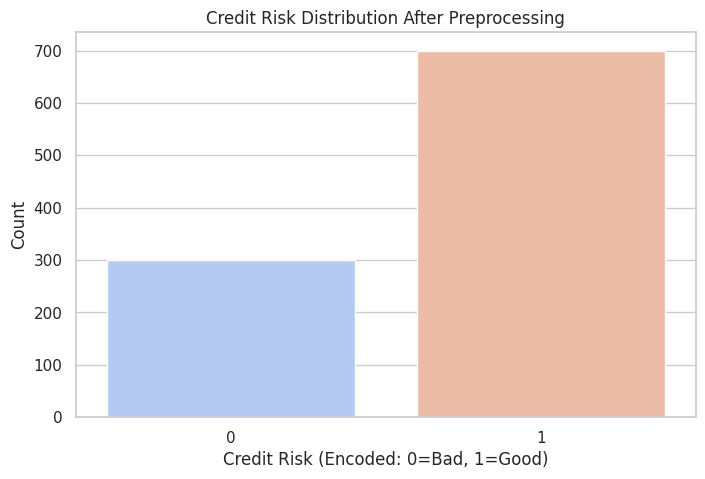

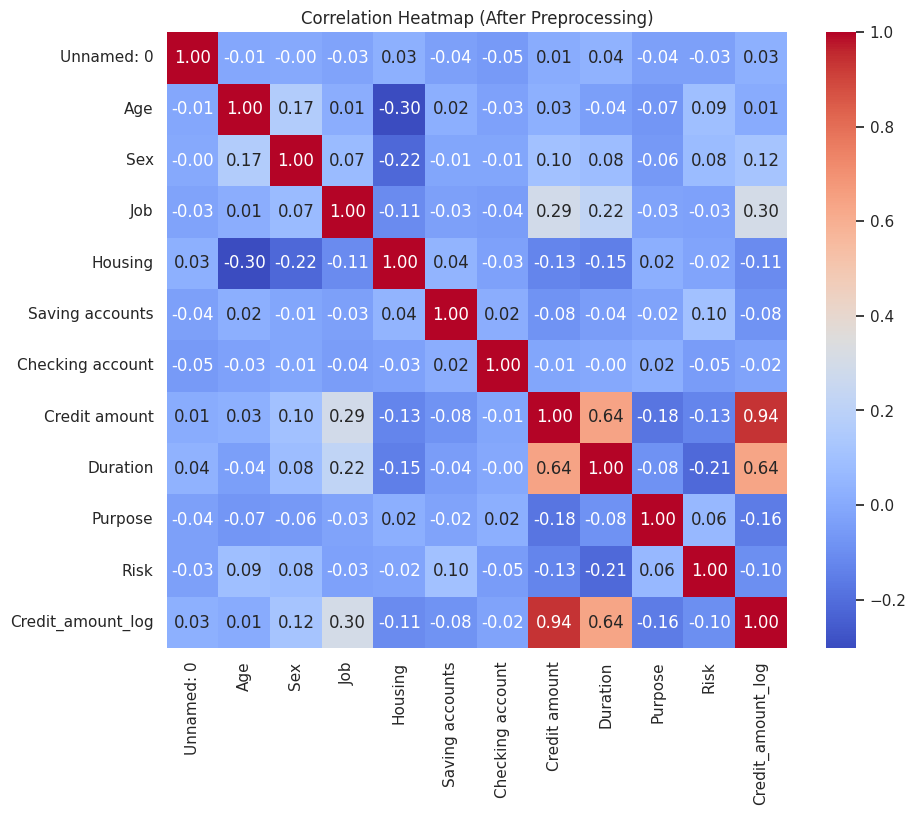

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

# 1) Load the original dataset
url = "https://raw.githubusercontent.com/saraalmazroa/-IT326-DataMining-Project-/main/Dataset/german_credit_data-3.csv"
df = pd.read_csv(url)

# Convert common missing value placeholders to standard NaN
df = df.replace(['NA','na','NaN','NULL','None',''], np.nan)

# --- Preprocessing steps matching your Phase 2 ---

# 1. Missing Values Handling (Mode Imputation)
cat_missing_cols = ['Saving accounts', 'Checking account']
freq_imputer = SimpleImputer(strategy='most_frequent')
df[cat_missing_cols] = freq_imputer.fit_transform(df[cat_missing_cols])

# 2. Outlier capping using the IQR method for numerical features
numeric_cols = ['Age', 'Credit amount', 'Duration']
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    # Cap values outside the IQR bounds
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

# 3. Variable Transformation (Log Transformation for Credit amount)
df["Credit_amount_log"] = np.log1p(df["Credit amount"])

# 4. Label encoding for all categorical attributes
# Making them suitable for Data Mining algorithms (Classification/Clustering)
categorical_cols = ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose', 'Risk']
label_encoder = LabelEncoder()
for col in categorical_cols:
    df[col] = df[col].astype(str) # Handle any potential type issues before encoding
    df[col] = label_encoder.fit_transform(df[col])

# 5. Min-Max Normalization for numerical variables
# Scaling numeric columns to a [0, 1] range to avoid dominating features
columns_to_normalize = ['Age', 'Credit amount', 'Duration', 'Credit_amount_log']
scaler = MinMaxScaler()
df[columns_to_normalize] = scaler.fit_transform(df[columns_to_normalize])

# 6. Save the preprocessed DataFrame
output_path = 'Preprocessed_dataset.csv' # Exact name requested in Phase 3 instructions
df.to_csv(output_path, index=False)

print(f"Preprocessed data successfully generated and saved to {output_path}")

# --- Display and Plotting (Using the preprocessed df) ---
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

print("\nData After Preprocessing:")
display(df.head())

print("\nSummary Statistics:")
display(df.describe())

# Plot 1: Class Label Distribution (Risk)
plt.figure()
sns.countplot(x="Risk", data=df, palette="coolwarm")
plt.title("Credit Risk Distribution After Preprocessing")
plt.xlabel("Credit Risk (Encoded: 0=Bad, 1=Good)")
plt.ylabel("Count")
plt.show()

# Plot 2: Correlation Heatmap
plt.figure(figsize=(10,8))
# Select only numeric columns for correlation calculation
numeric_df = df.select_dtypes(include=[np.number])
# Using annot=True to show the correlation values on the heatmap
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap (After Preprocessing)")
plt.show()

# **5-Data Mining Technique**

In this project, our group will apply two main data mining techniques: classification and clustering, using Python and standard machine-learning libraries. For classification, we will use a Decision Tree Classifier from sklearn.tree to predict customer credit risk (Good or Bad) based on financial and personal attributes such as credit amount, duration, age, and housing. Decision trees are chosen for their interpretability, their ability to handle mixed data types, and their effectiveness in extracting clear approval or rejection rules for bank loans using both Gini and Entropy criteria. Model performance will be evaluated across different data splits using accuracy and a confusion matrix visualized with ConfusionMatrixDisplay from sklearn.metrics.

For clustering, we will apply K-Means from sklearn.cluster to group customers based on similarities in their financial exposure (specifically focusing on normalized loan duration and log-transformed credit amount), independent of the actual risk labels. This unsupervised approach helps reveal hidden patterns, such as identifying distinct subgroups of customers with high versus low financial exposure. We will use the Elbow Method and the Silhouette Coefficient to determine the optimal number of clusters (K). Throughout the process, Pandas, NumPy, Matplotlib, and Seaborn will be used for data preprocessing, statistical analysis, and visual integration.

In [ ]:
# Load libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn import tree
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


In [ ]:
# Load data
url = "https://raw.githubusercontent.com/saraalmazroa/-IT326-DataMining-Project-/main/Dataset/Preprocessed_data.csv"
df = pd.read_csv(url, index_col=0)   # index_col=0 removes the extra "Unnamed: 0" column
print(df.head())   # get the first 5 rows

                 Age     Sex  Job Housing Saving accounts Checking account  \
Unnamed: 0                                                                   
0           1.000000    male    2     own          little           little   
1           0.065934  female    2     own          little         moderate   
2           0.659341    male    1     own          little           little   
3           0.571429    male    2    free          little           little   
4           0.747253    male    2    free          little           little   

            Credit amount  Duration              Purpose  Risk  \
Unnamed: 0                                                       
0                0.120408  0.052632             radio/TV  good   
1                0.746950  1.000000             radio/TV   bad   
2                0.241864  0.210526            education  good   
3                0.999951  1.000000  furniture/equipment  good   
4                0.605316  0.526316                  car 

## Classification – Gini Index: 90% training / 10% testing

In [ ]:
# Feature Selection: split dataset in features and target variable
# If you have an ID column you should drop it before the training process
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set
X_train_90, X_test_90, y_train_90, y_test_90 = train_test_split(X, y, test_size=0.1, random_state=1)   # 90% training and 10% test

# Create Decision Tree classifier object (default criterion is Gini)
clf_90 = DecisionTreeClassifier(criterion="gini", random_state=1)

# Train Decision Tree Classifier
clf_90 = clf_90.fit(X_train_90, y_train_90)

# Predict the response for test dataset
y_pred_90 = clf_90.predict(X_test_90)

# Model Accuracy, how often is the classifier correct?
acc_90 = metrics.accuracy_score(y_test_90, y_pred_90)
print("Accuracy:", acc_90)

Accuracy: 0.64


### Confusion matrix (90/10)


[[13 17]
 [19 51]]


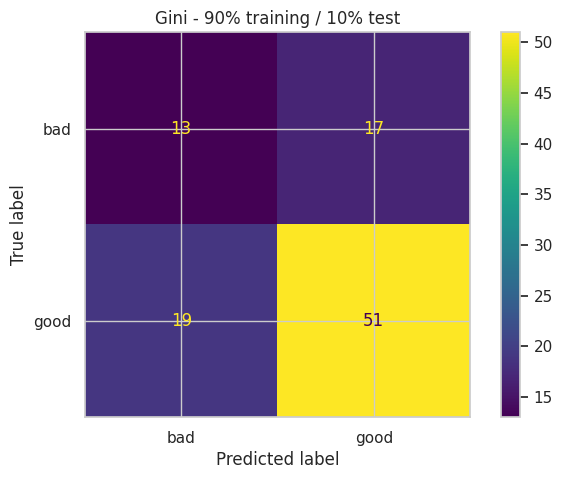

In [ ]:
# Compute and print the confusion matrix
cm_90 = confusion_matrix(y_test_90, y_pred_90)
print(cm_90)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_90, X_test_90, y_test_90, display_labels=cn)
plt.title("Gini - 90% training / 10% test")
plt.show()

### Decision tree plot (90/10)


Accuracy of the pruned tree (for the plot only): 0.7


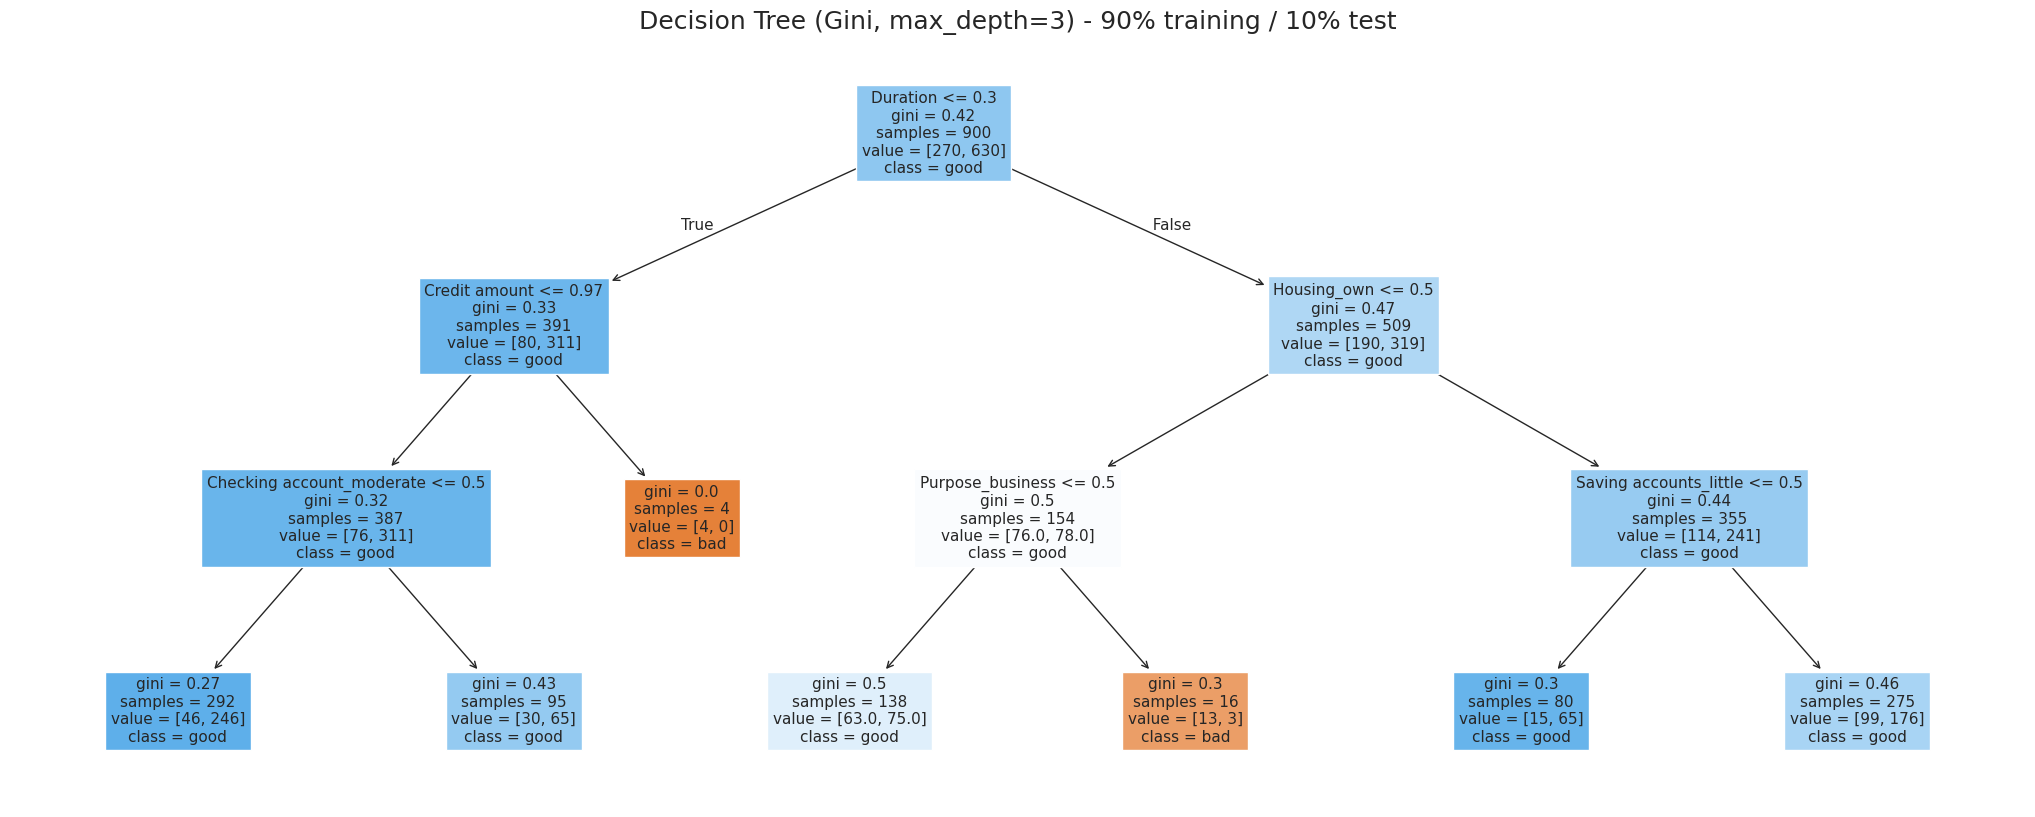

In [ ]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_90_plot = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=1)
clf_90_plot = clf_90_plot.fit(X_train_90, y_train_90)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_90, clf_90_plot.predict(X_test_90)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_90_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Gini, max_depth=3) - 90% training / 10% test", fontsize=18)
fig.savefig('gini_DT_90_10.png', dpi=300, bbox_inches='tight')   # You can save your plot if you want
plt.show()

## Classification – Gini Index: 80% training / 20% testing


In [ ]:
# Feature Selection: split dataset in features and target variable
# If you have an ID column you should drop it before the training process
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set
X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(X, y, test_size=0.2, random_state=1)   # 80% training and 20% test

# Create Decision Tree classifier object (default criterion is Gini)
clf_80 = DecisionTreeClassifier(criterion="gini", random_state=1)

# Train Decision Tree Classifier
clf_80 = clf_80.fit(X_train_80, y_train_80)

# Predict the response for test dataset
y_pred_80 = clf_80.predict(X_test_80)

# Model Accuracy, how often is the classifier correct?
acc_80 = metrics.accuracy_score(y_test_80, y_pred_80)
print("Accuracy:", acc_80)

Accuracy: 0.66


### Confusion matrix (80/20)


[[ 26  33]
 [ 35 106]]


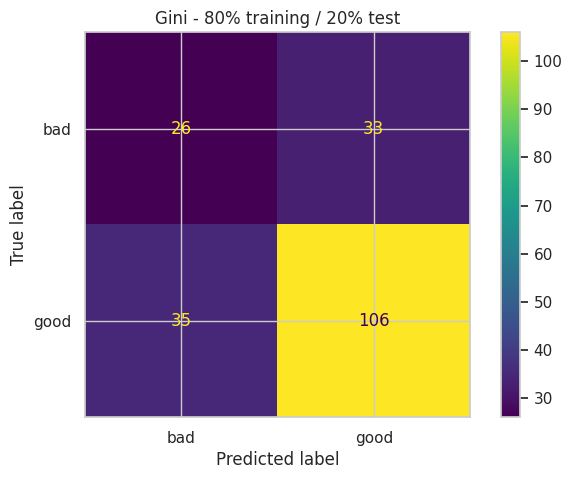

In [ ]:
# Compute and print the confusion matrix
cm_80 = confusion_matrix(y_test_80, y_pred_80)
print(cm_80)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_80, X_test_80, y_test_80, display_labels=cn)
plt.title("Gini - 80% training / 20% test")
plt.show()

### Decision tree plot (80/20)


Accuracy of the pruned tree (for the plot only): 0.71


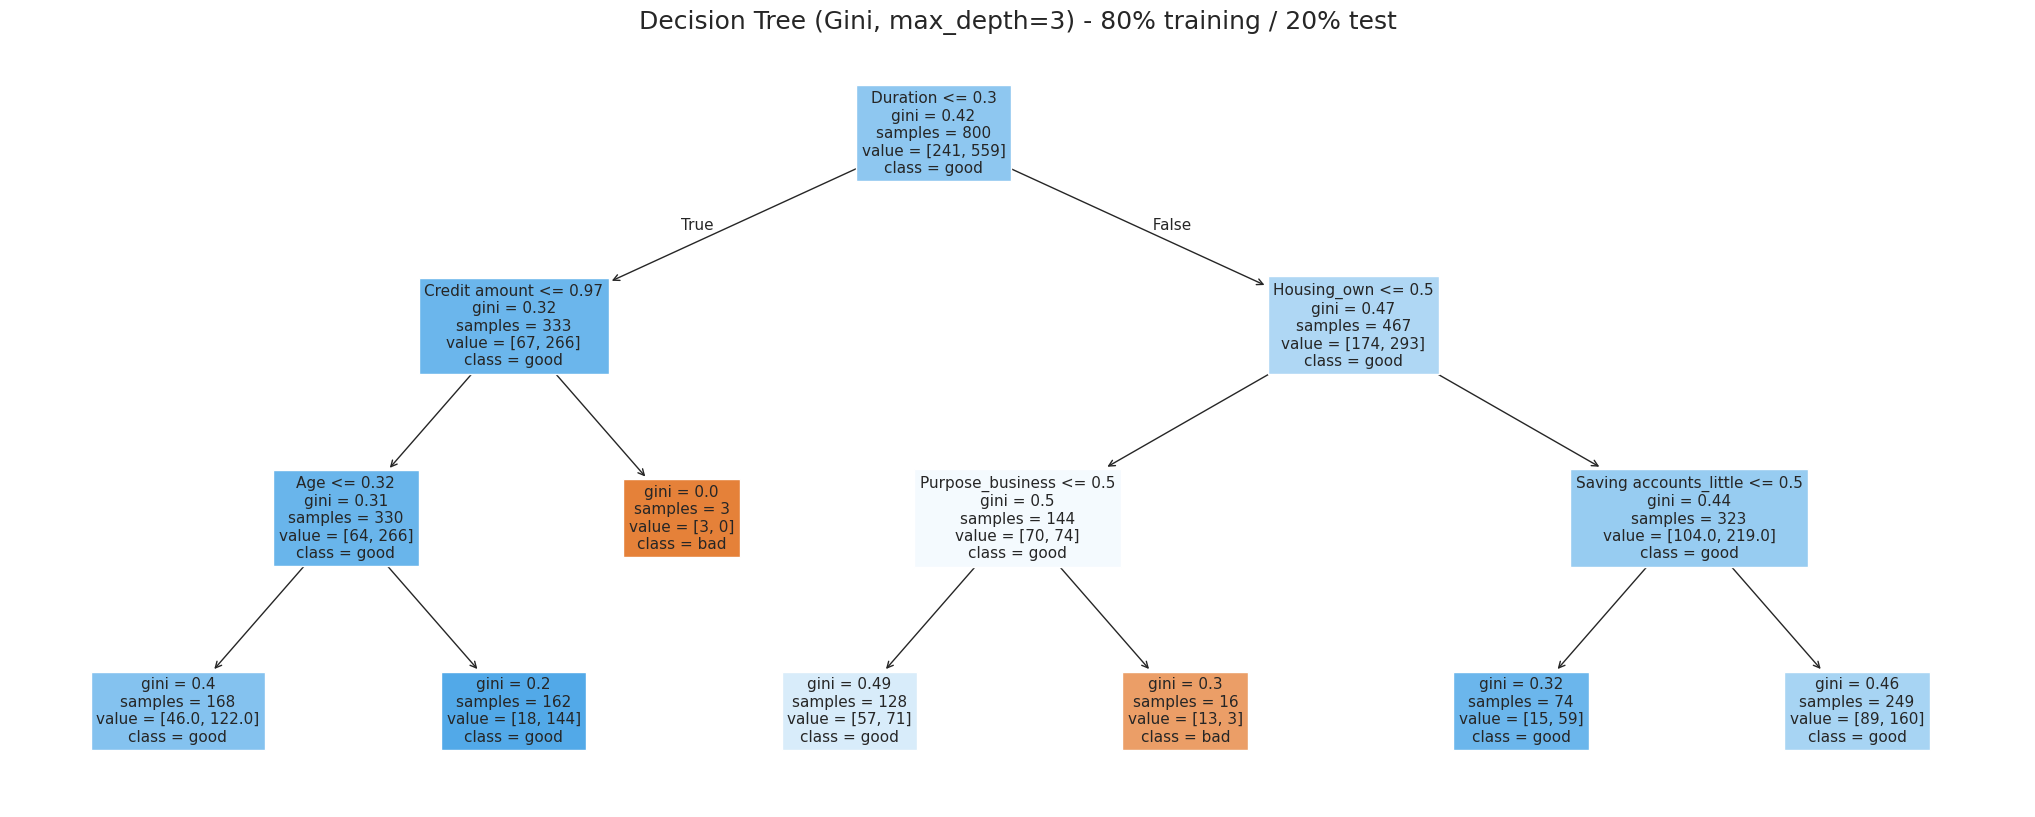

In [ ]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_80_plot = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=1)
clf_80_plot = clf_80_plot.fit(X_train_80, y_train_80)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_80, clf_80_plot.predict(X_test_80)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_80_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Gini, max_depth=3) - 80% training / 20% test", fontsize=18)
fig.savefig('gini_DT_80_20.png', dpi=300, bbox_inches='tight')   # You can save your plot if you want
plt.show()

## Classification – Gini Index: 70% training / 30% testing


In [ ]:
# Feature Selection: split dataset in features and target variable
# If you have an ID column you should drop it before the training process
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set
X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(X, y, test_size=0.3, random_state=1)   # 70% training and 30% test

# Create Decision Tree classifier object (default criterion is Gini)
clf_70 = DecisionTreeClassifier(criterion="gini", random_state=1)

# Train Decision Tree Classifier
clf_70 = clf_70.fit(X_train_70, y_train_70)

# Predict the response for test dataset
y_pred_70 = clf_70.predict(X_test_70)

# Model Accuracy, how often is the classifier correct?
acc_70 = metrics.accuracy_score(y_test_70, y_pred_70)
print("Accuracy:", acc_70)

Accuracy: 0.6233333333333333


### Confusion matrix (70/30)


[[ 34  52]
 [ 61 153]]


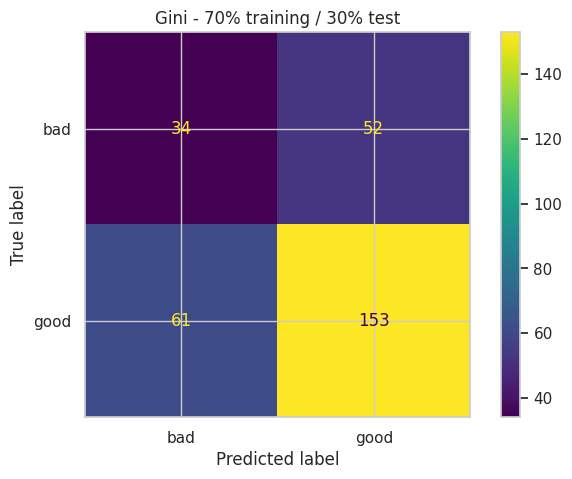

In [ ]:
# Compute and print the confusion matrix
cm_70 = confusion_matrix(y_test_70, y_pred_70)
print(cm_70)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_70, X_test_70, y_test_70, display_labels=cn)
plt.title("Gini - 70% training / 30% test")
plt.show()

### Decision tree plot (70/30)


Accuracy of the pruned tree (for the plot only): 0.7


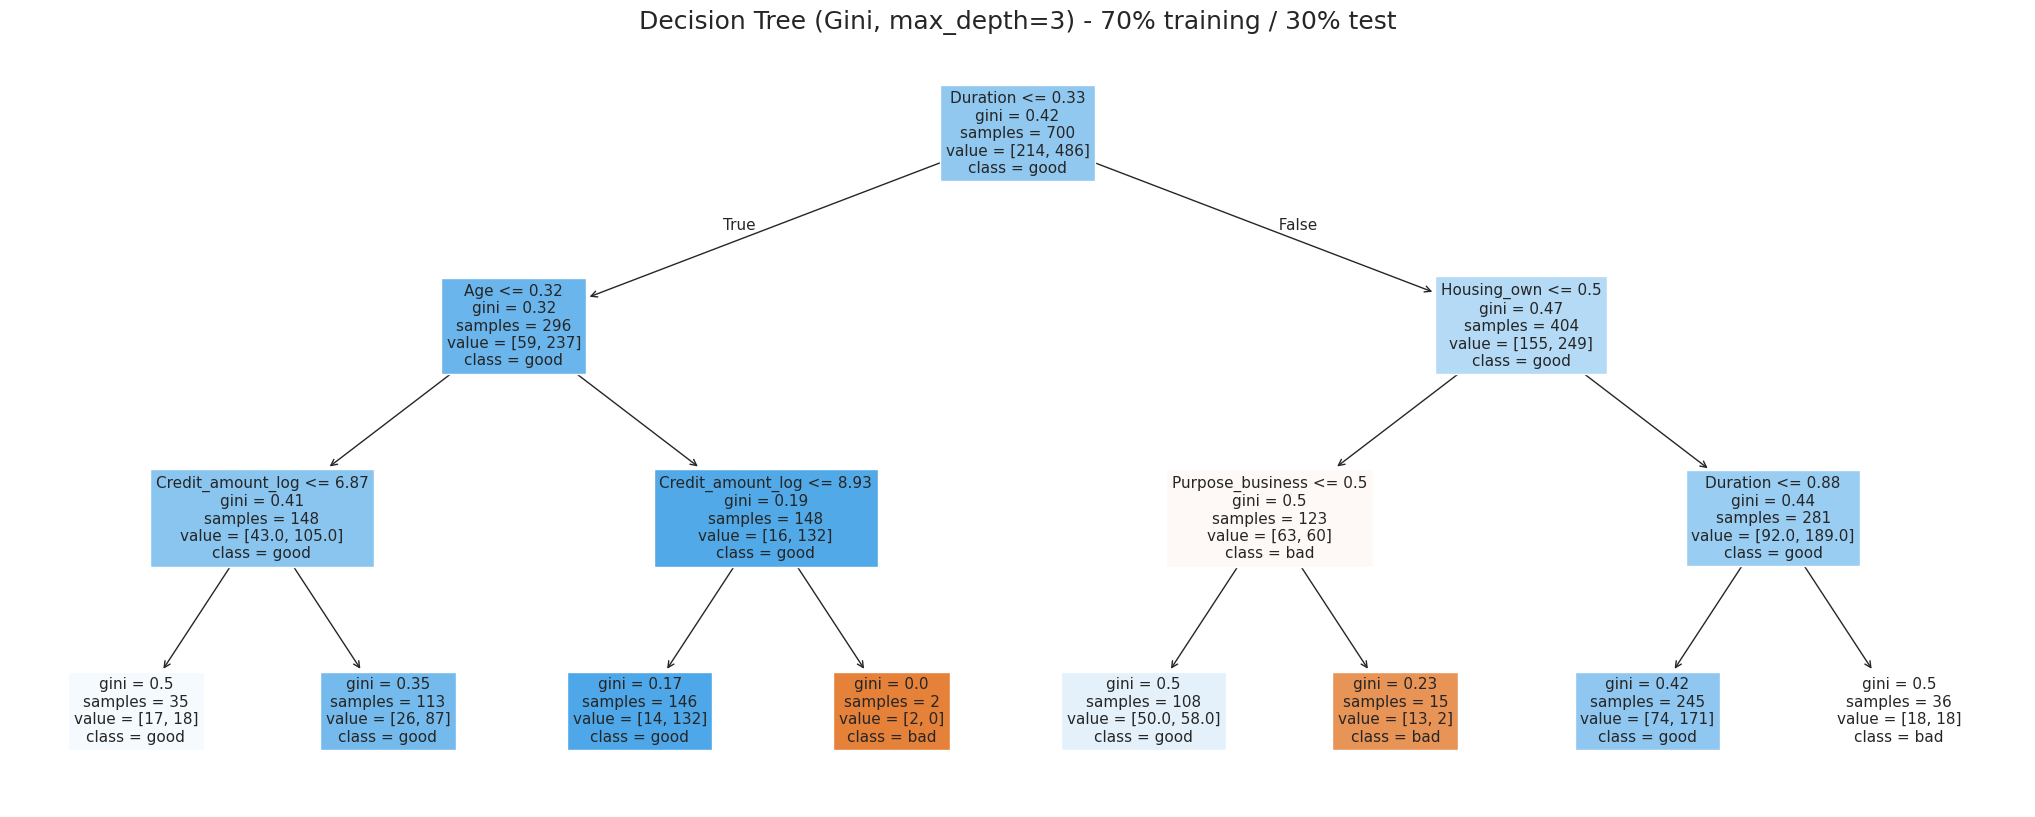

In [ ]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_70_plot = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=1)
clf_70_plot = clf_70_plot.fit(X_train_70, y_train_70)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_70, clf_70_plot.predict(X_test_70)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_70_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Gini, max_depth=3) - 70% training / 30% test", fontsize=18)
fig.savefig('gini_DT_70_30.png', dpi=300, bbox_inches='tight')   # You can save your plot if you want
plt.show()

### Gini index – accuracy summary table


In [ ]:
gini_table = pd.DataFrame(
    [[round(acc_90, 4), round(acc_80, 4), round(acc_70, 4)]],
    index=["Accuracy"],
    columns=["90% training set 10% testing set",
             "80% training set 20% testing set",
             "70% training set 30% testing set"])
gini_table

,90% training set 10% testing set,80% training set 20% testing set,70% training set 30% testing set
Accuracy,0.64,0.66,0.6233


## Classification – Information Gain (Entropy)

The second attribute selection measure is **Information Gain (IG)**, based on entropy.

- **Entropy** measures the impurity of a node: $Entropy(D) = -\sum_{i=1}^{m} p_i \log_2(p_i)$
- **Information Gain** of attribute A: $Gain(A) = Entropy(D) - \sum_{j=1}^{v} \frac{|D_j|}{|D|} \times Entropy(D_j)$
- At each node, the tree chooses the attribute with the **highest information gain**: the split that reduces the uncertainty about the class (good / bad) the most.

We use `DecisionTreeClassifier(criterion="entropy")` with the **same settings as the Gini section** (same features, `random_state=1`, same three partitions), so the only difference between the two models is the attribute selection measure.


## Classification – Information Gain (Entropy): 90% training / 10% testing

In [ ]:
# Feature Selection: split dataset in features and target variable
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set (same random_state as Gini -> same partition)
X_train_90, X_test_90, y_train_90, y_test_90 = train_test_split(X, y, test_size=0.1, random_state=1)   # 90% training and 10% test

# Create Decision Tree classifier object using Information Gain
clf_90_e = DecisionTreeClassifier(criterion="entropy", random_state=1)

# Train Decision Tree Classifier
clf_90_e = clf_90_e.fit(X_train_90, y_train_90)

# Predict the response for test dataset
y_pred_90_e = clf_90_e.predict(X_test_90)

# Model Accuracy, how often is the classifier correct?
acc_90_e = metrics.accuracy_score(y_test_90, y_pred_90_e)
print("Accuracy:", acc_90_e)

Accuracy: 0.6


### Confusion matrix (90/10)

[[10 20]
 [20 50]]


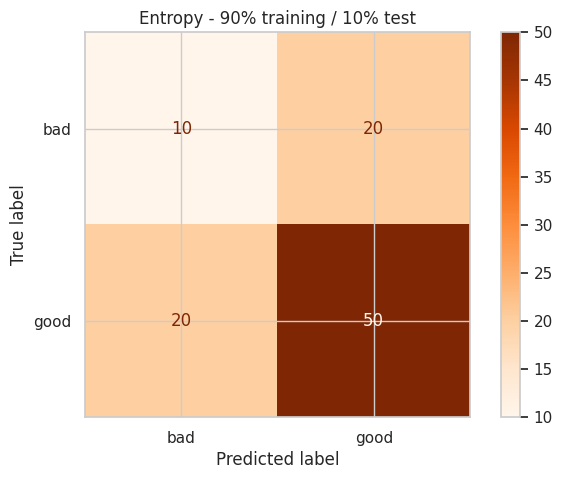

In [ ]:
# Compute and print the confusion matrix
cm_90_e = confusion_matrix(y_test_90, y_pred_90_e)
print(cm_90_e)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_90_e, X_test_90, y_test_90, display_labels=cn, cmap="Oranges")
plt.title("Entropy - 90% training / 10% test")
plt.show()

### Decision tree plot (90/10)

Accuracy of the pruned tree (for the plot only): 0.7


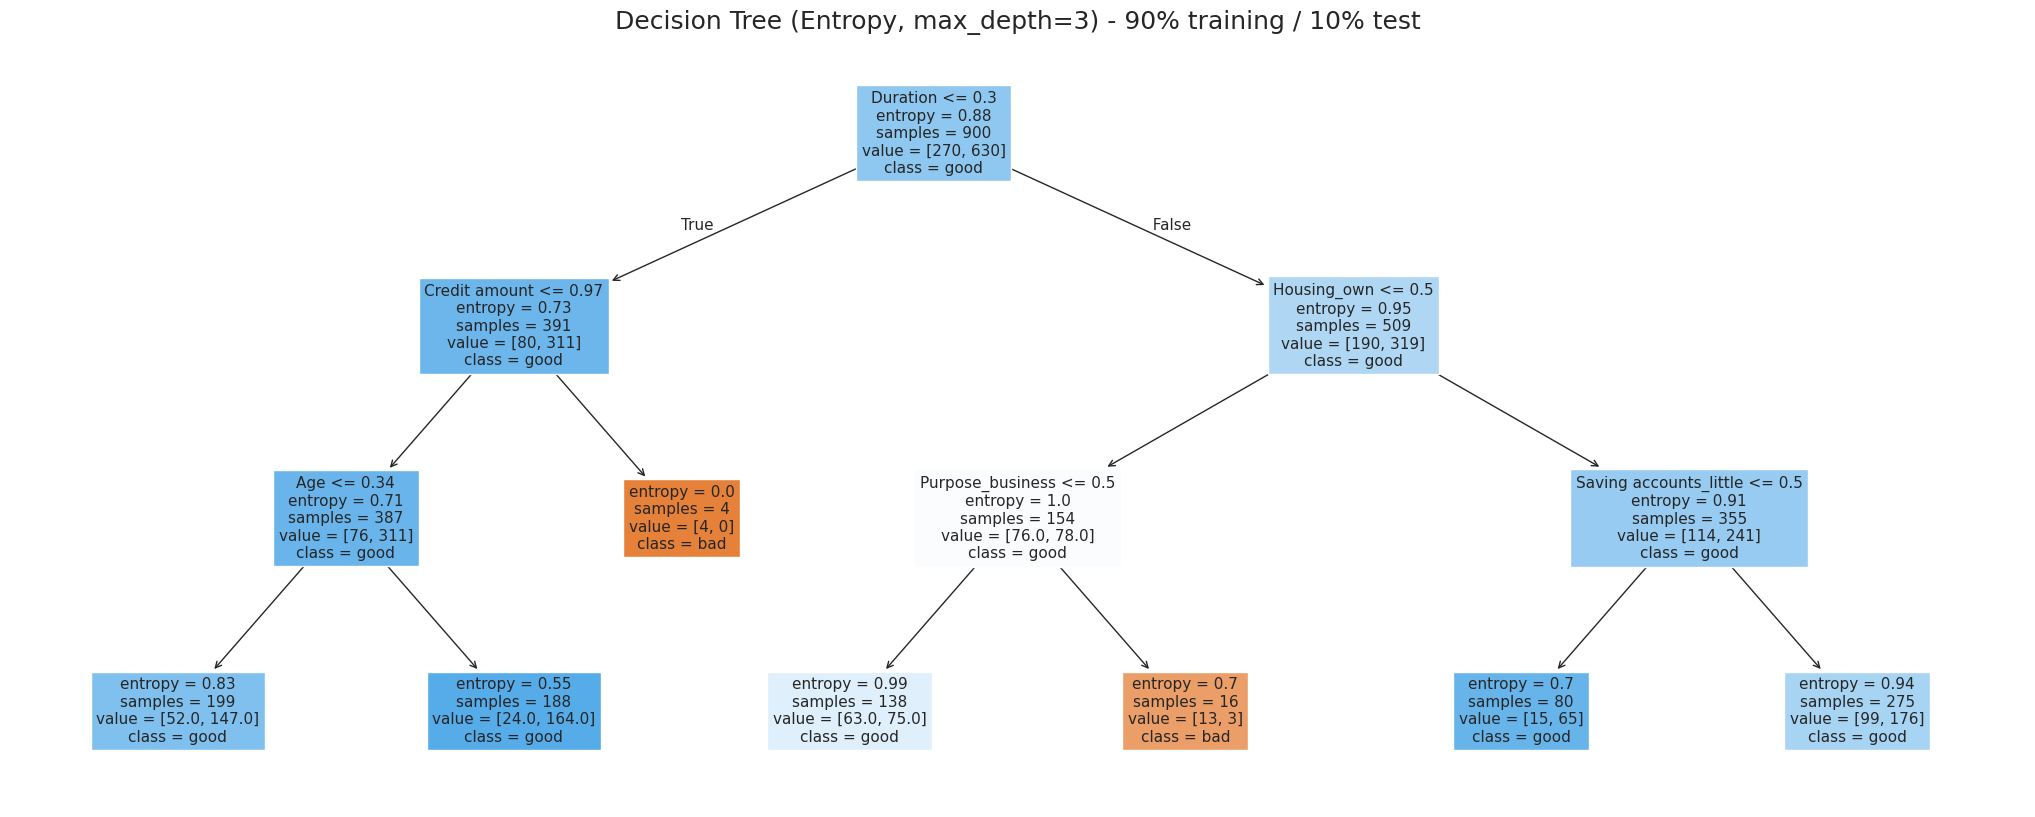

In [ ]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_90_e_plot = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=1)
clf_90_e_plot = clf_90_e_plot.fit(X_train_90, y_train_90)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_90, clf_90_e_plot.predict(X_test_90)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_90_e_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Entropy, max_depth=3) - 90% training / 10% test", fontsize=18)
fig.savefig('entropy_DT_90_10.png', dpi=300, bbox_inches='tight')
plt.show()

## Classification – Information Gain (Entropy): 80% training / 20% testing

In [ ]:
# Feature Selection: split dataset in features and target variable
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set (same random_state as Gini -> same partition)
X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(X, y, test_size=0.2, random_state=1)   # 80% training and 20% test

# Create Decision Tree classifier object using Information Gain
clf_80_e = DecisionTreeClassifier(criterion="entropy", random_state=1)

# Train Decision Tree Classifier
clf_80_e = clf_80_e.fit(X_train_80, y_train_80)

# Predict the response for test dataset
y_pred_80_e = clf_80_e.predict(X_test_80)

# Model Accuracy, how often is the classifier correct?
acc_80_e = metrics.accuracy_score(y_test_80, y_pred_80_e)
print("Accuracy:", acc_80_e)

Accuracy: 0.585


### Confusion matrix (80/20)

[[19 40]
 [43 98]]


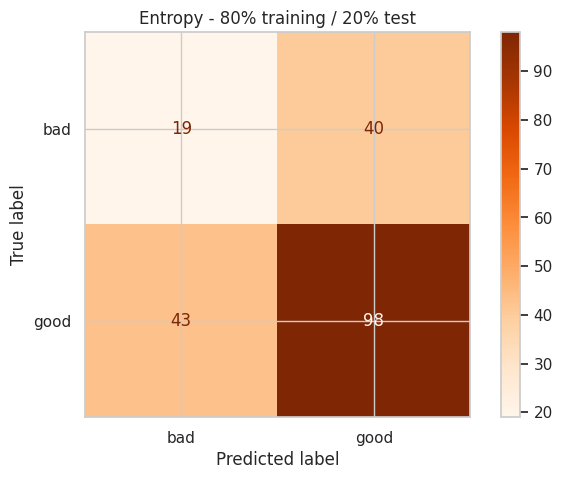

In [ ]:
# Compute and print the confusion matrix
cm_80_e = confusion_matrix(y_test_80, y_pred_80_e)
print(cm_80_e)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_80_e, X_test_80, y_test_80, display_labels=cn, cmap="Oranges")
plt.title("Entropy - 80% training / 20% test")
plt.show()

### Decision tree plot (80/20)

Accuracy of the pruned tree (for the plot only): 0.71


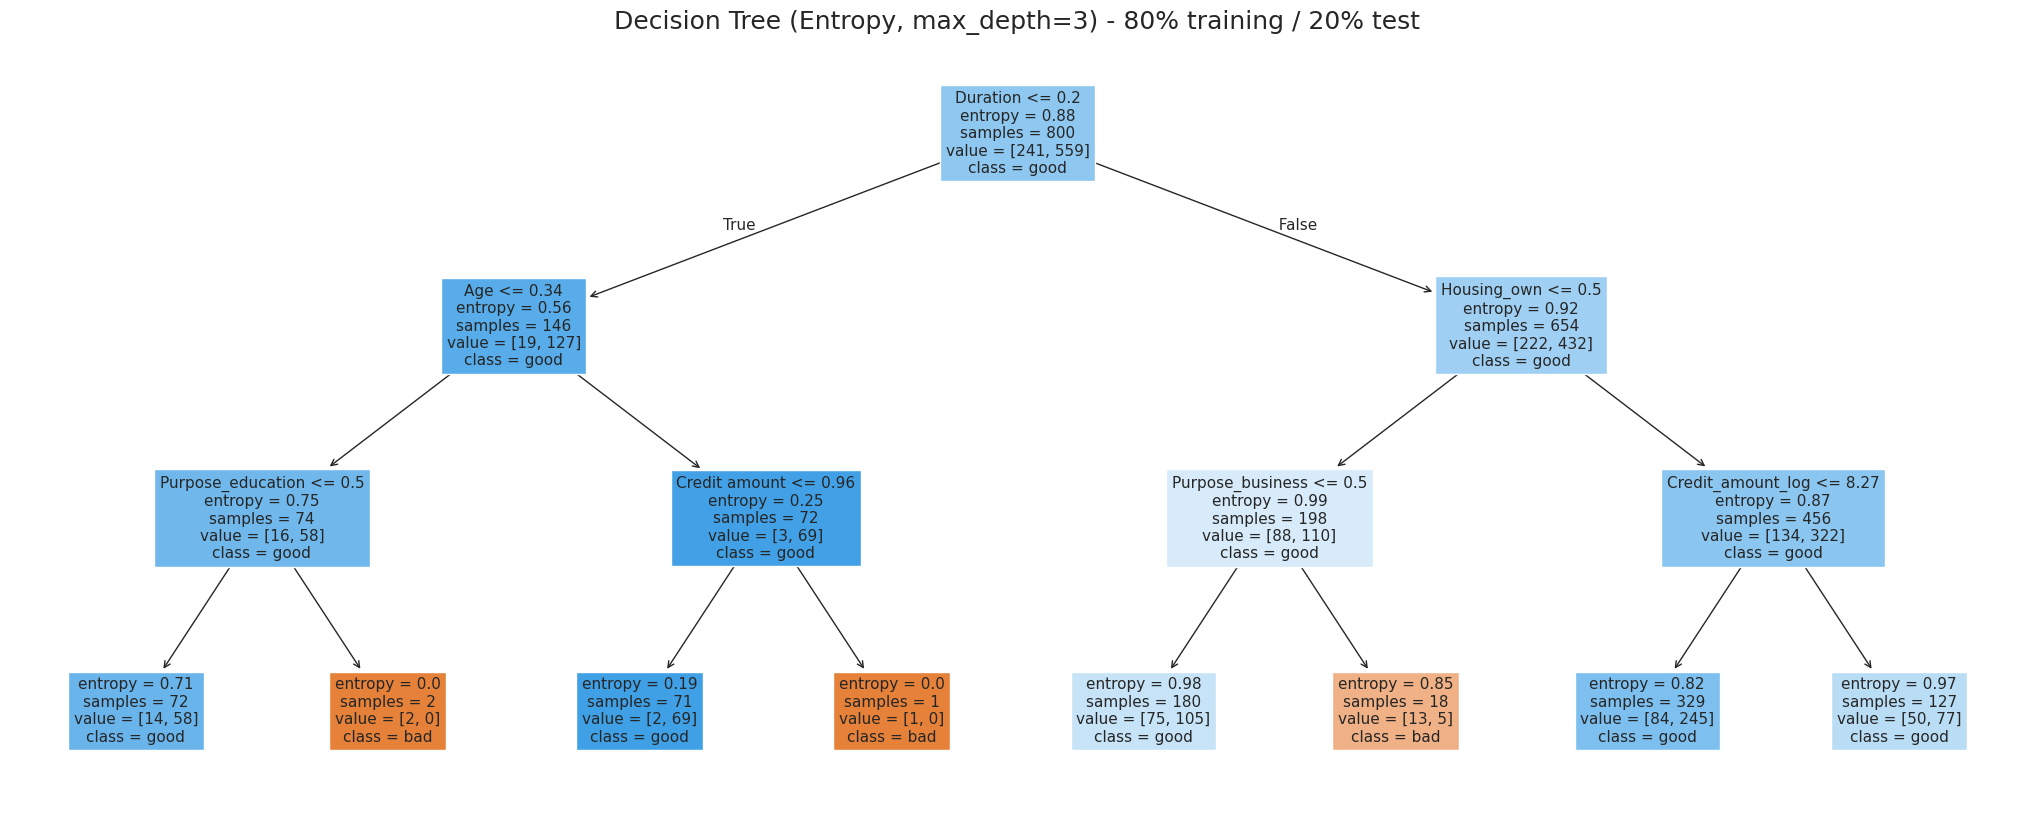

In [ ]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_80_e_plot = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=1)
clf_80_e_plot = clf_80_e_plot.fit(X_train_80, y_train_80)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_80, clf_80_e_plot.predict(X_test_80)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_80_e_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Entropy, max_depth=3) - 80% training / 20% test", fontsize=18)
fig.savefig('entropy_DT_80_20.png', dpi=300, bbox_inches='tight')
plt.show()

## Classification – Information Gain (Entropy): 70% training / 30% testing

In [ ]:
# Feature Selection: split dataset in features and target variable
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set (same random_state as Gini -> same partition)
X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(X, y, test_size=0.3, random_state=1)   # 70% training and 30% test

# Create Decision Tree classifier object using Information Gain
clf_70_e = DecisionTreeClassifier(criterion="entropy", random_state=1)

# Train Decision Tree Classifier
clf_70_e = clf_70_e.fit(X_train_70, y_train_70)

# Predict the response for test dataset
y_pred_70_e = clf_70_e.predict(X_test_70)

# Model Accuracy, how often is the classifier correct?
acc_70_e = metrics.accuracy_score(y_test_70, y_pred_70_e)
print("Accuracy:", acc_70_e)

Accuracy: 0.6366666666666667


### Confusion matrix (70/30)

[[ 37  49]
 [ 60 154]]


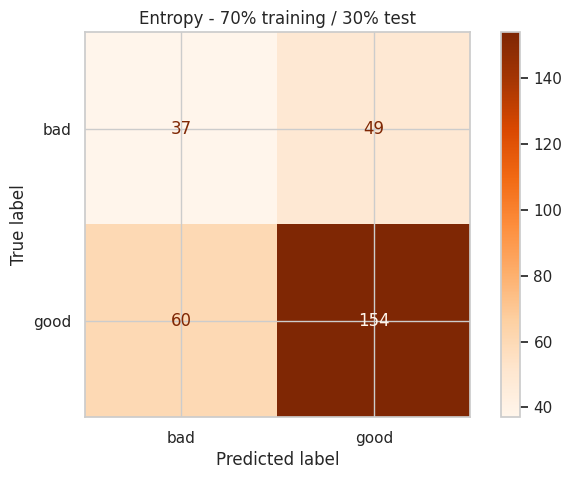

In [ ]:
# Compute and print the confusion matrix
cm_70_e = confusion_matrix(y_test_70, y_pred_70_e)
print(cm_70_e)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_70_e, X_test_70, y_test_70, display_labels=cn, cmap="Oranges")
plt.title("Entropy - 70% training / 30% test")
plt.show()

### Decision tree plot (70/30)

Accuracy of the pruned tree (for the plot only): 0.7


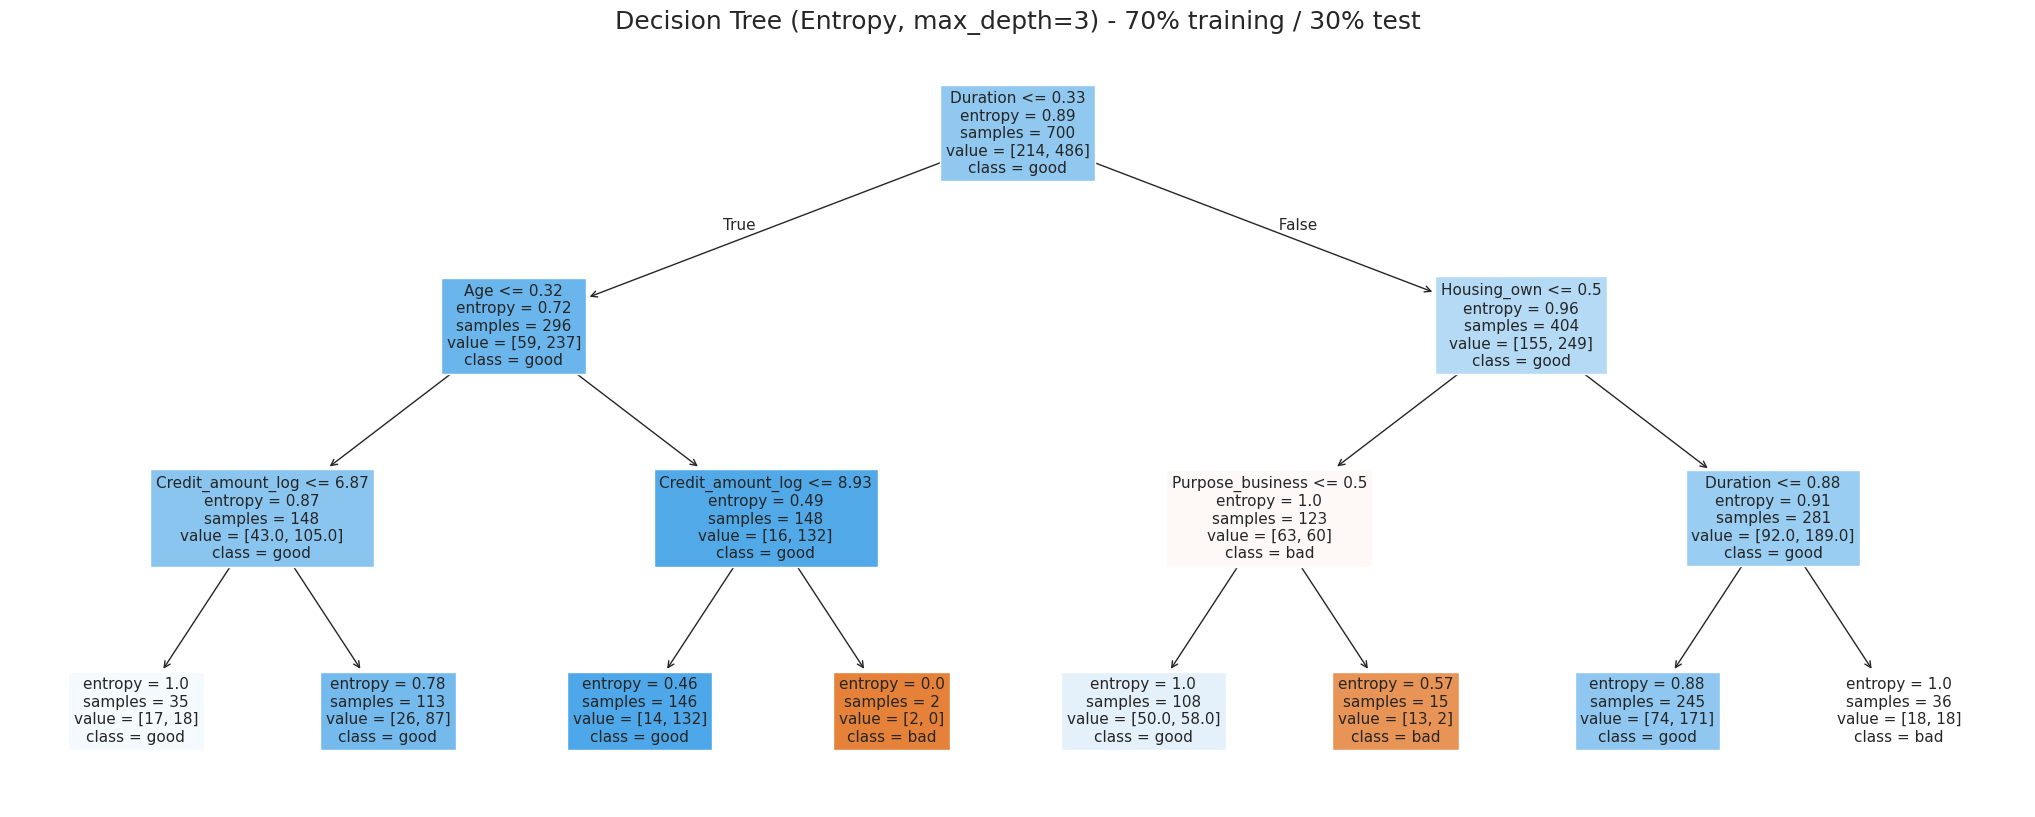

In [ ]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_70_e_plot = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=1)
clf_70_e_plot = clf_70_e_plot.fit(X_train_70, y_train_70)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_70, clf_70_e_plot.predict(X_test_70)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_70_e_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Entropy, max_depth=3) - 70% training / 30% test", fontsize=18)
fig.savefig('entropy_DT_70_30.png', dpi=300, bbox_inches='tight')
plt.show()

### Information Gain (Entropy) – accuracy summary table

In [ ]:
entropy_table = pd.DataFrame(
    [[round(acc_90_e, 4), round(acc_80_e, 4), round(acc_70_e, 4)]],
    index=["Accuracy"],
    columns=["90% training set 10% testing set",
             "80% training set 20% testing set",
             "70% training set 30% testing set"])
entropy_table

,90% training set 10% testing set,80% training set 20% testing set,70% training set 30% testing set
Accuracy,0.6,0.585,0.6367


# **6-Evaluation and Comparison – Classification**

In [ ]:
# Accuracy of both attribute selection measures for all partitions
comparison = pd.DataFrame(
    [[acc_90_e, acc_80_e, acc_70_e],
     [acc_90,   acc_80,   acc_70]],
    index=["IG (Entropy)", "Gini index"],
    columns=["90% training set 10% testing set",
             "80% training set 20% testing set",
             "70% training set 30% testing set"])
comparison["Average"] = comparison.mean(axis=1)
comparison.round(4)

,90% training set 10% testing set,80% training set 20% testing set,70% training set 30% testing set,Average
IG (Entropy),0.60,0.585,0.6367,0.6072
Gini index,0.64,0.660,0.6233,0.6411


In [ ]:
# Best measure for each partition and overall
for split in comparison.columns[:3]:
    print(f"{split}: best = {comparison[split].idxmax()} ({comparison[split].max():.2%})")
print(f"\nBest overall (average accuracy): {comparison['Average'].idxmax()} ({comparison['Average'].max():.2%})")

90% training set 10% testing set: best = Gini index (64.00%)
80% training set 20% testing set: best = Gini index (66.00%)
70% training set 30% testing set: best = IG (Entropy) (63.67%)

Best overall (average accuracy): Gini index (64.11%)


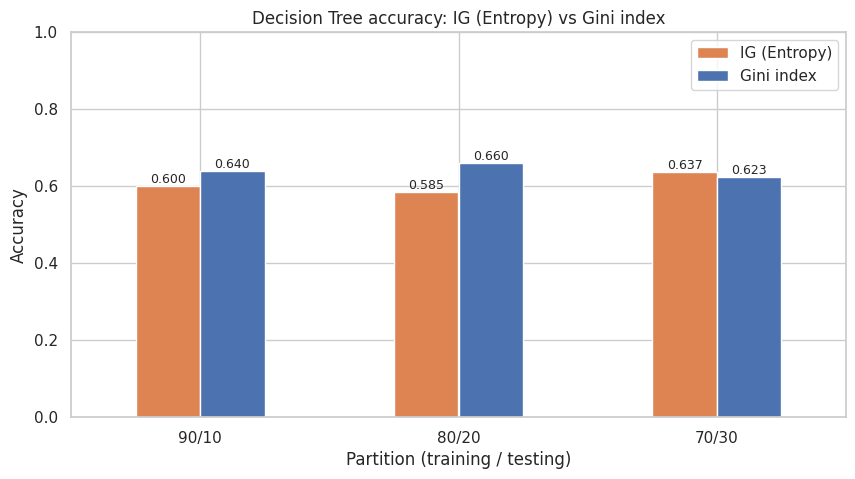

In [ ]:
# Visual comparison of accuracy
ax = comparison.drop(columns="Average").T.plot(kind="bar", figsize=(10, 5), rot=0, color=["#DD8452", "#4C72B0"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=9)
ax.set_xticklabels(["90/10", "80/20", "70/30"])
ax.set_xlabel("Partition (training / testing)")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.set_title("Decision Tree accuracy: IG (Entropy) vs Gini index")
plt.show()

**IG (Entropy):**

| | 90% training set 10% testing set | 80% training set 20% testing set | 70% training set 30% testing set |
|---|---|---|---|
| Accuracy | 60.00% | 58.50% | 63.67% |

**Gini index:**

| | 90% training set 10% testing set | 80% training set 20% testing set | 70% training set 30% testing set |
|---|---|---|---|
| Accuracy | 64.00% | 66.00% | 62.33% |

**Confusion matrices – bad customers detected (out of all actual bad customers in the test set):**

| Split | Entropy | Gini |
|---|---|---|
| 90/10 | 10 / 30 | 13 / 30 |
| 80/20 | 19 / 59 | 26 / 59 |
| 70/30 | 37 / 86 | 34 / 86 |

**Best per partition:**
- **90/10:** Gini (64.00% vs 60.00%), and it also detects more bad customers (13 vs 10).
- **80/20:** Gini (66.00% vs 58.50%), and it also detects more bad customers (26 vs 19).
- **70/30:** Entropy (63.67% vs 62.33%), and it also detects more bad customers (37 vs 34).

**Best overall:** **Gini index**, with an average accuracy of **64.11%** vs **60.72%** for Entropy, winning two of the three partitions.

**Discussion:**
- The two measures give close results because both estimate node impurity in a similar way. They mostly choose the same attributes near the root of the tree and differ in the lower levels, where few records remain and small differences change the predictions.
- The model with higher accuracy also detected more bad customers in every partition, so accuracy and the confusion matrix agree on the winner.
- The dataset is imbalanced (70% good / 30% bad), so a model that always predicts "good" would reach about 70% accuracy. Both full trees are below this level, which means accuracy alone is not enough to judge them; the confusion matrix shows that both models miss more than half of the bad customers, which is the costliest error for a bank.

In [ ]:
# Overfitting check: training vs testing accuracy of the full trees
fit_check = pd.DataFrame({
    "Model": ["Entropy 90/10", "Entropy 80/20", "Entropy 70/30", "Gini 90/10", "Gini 80/20", "Gini 70/30"],
    "Tree depth": [m.get_depth() for m in [clf_90_e, clf_80_e, clf_70_e, clf_90, clf_80, clf_70]],
    "Leaves": [m.get_n_leaves() for m in [clf_90_e, clf_80_e, clf_70_e, clf_90, clf_80, clf_70]],
    "Training accuracy": [clf_90_e.score(X_train_90, y_train_90), clf_80_e.score(X_train_80, y_train_80), clf_70_e.score(X_train_70, y_train_70),
                          clf_90.score(X_train_90, y_train_90),   clf_80.score(X_train_80, y_train_80),   clf_70.score(X_train_70, y_train_70)],
    "Testing accuracy": [acc_90_e, acc_80_e, acc_70_e, acc_90, acc_80, acc_70]})
fit_check.round(4)

,Model,Tree depth,Leaves,Training accuracy,Testing accuracy
0,Entropy 90/10,19,232,1.0,0.6000
1,Entropy 80/20,22,205,1.0,0.5850
2,Entropy 70/30,20,178,1.0,0.6367
3,Gini 90/10,16,228,1.0,0.6400
4,Gini 80/20,15,206,1.0,0.6600
5,Gini 70/30,20,182,1.0,0.6233


**Overfitting:** the full trees reach **100% training accuracy** with a depth of about 20, but only 58–66% on the testing data. The trees memorize the training records instead of learning general rules, which explains why both measures stay below the 70% baseline and why the results do not improve steadily as the training set grows.

#Clustering

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

url = "https://raw.githubusercontent.com/saraalmazroa/-IT326-DataMining-Project-/main/Dataset/Preprocessed_data.csv"

df = pd.read_csv(url)

# Checking that the dataset loaded
print(df.shape)
display(df.head())

(1000, 12)


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk,Credit_amount_log
0,0,1.000000,male,2,own,little,little,0.120408,0.052632,radio/TV,good,7.064759
1,1,0.065934,female,2,own,little,moderate,0.746950,1.000000,radio/TV,bad,8.691483
2,2,0.659341,male,1,own,little,little,0.241864,0.210526,education,good,7.648263
3,3,0.571429,male,2,free,little,little,0.999951,1.000000,furniture/equipment,good,8.972464
4,4,0.747253,male,2,free,little,little,0.605316,0.526316,car,bad,8.491055


###Preparing Data For Clustering

In [ ]:
# Remove the class label and index column
X = df.drop(columns=["Risk", "Unnamed: 0"], errors="ignore")

# Convert categorical columns into numbers
X = pd.get_dummies(X, dtype=int)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data prepared successfully")
print("Shape:", X_scaled.shape)

Data prepared successfully
Shape: (1000, 25)


###Calculate WSS For Different K Values

In [ ]:
wss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wss.append(kmeans.inertia_)

wss_table = pd.DataFrame({
    "K": list(K_range),
    "WSS": wss
})
display(wss_table.round(2))

,K,WSS
0,1,25000.00
1,2,22834.73
2,3,21259.01
3,4,20148.98
4,5,19027.57
5,6,18252.46
6,7,17104.29
7,8,16473.35
8,9,15741.95
9,10,14735.25


###Elpow plot

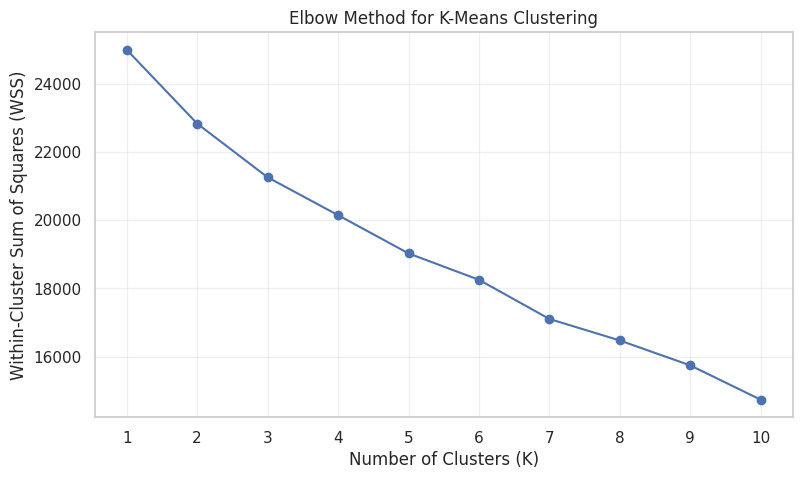

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(
    list(K_range),
    wss,
    marker="o",
    linestyle="-"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (WSS)")
plt.title("Elbow Method for K-Means Clustering")
plt.xticks(list(K_range))
plt.grid(True, alpha=0.3)
plt.show()


The results show that WSS decreases as K increases. The largest improvements occur at the beginning of the graph, but there is no clear elbow point.

Therefore, K = 2, K = 3, and K = 4 were selected for further evaluation because they represent the early region where WSS decreases significantly. These values will be compared using the Silhouette Coefficient to help determine the optimal number of clusters.

##[5]K-Means Clustering

K-Means is an unsupervised learning algorithm that divides data into K groups (clusters) based on their similarities. Each group contains data points that have similar characteristics.

The algorithm works by selecting K cluster centers (centroids), assigning each data point to the nearest center, and updating the centers until the clusters become stable.

In our project, K-Means is used to group customers with similar credit characteristics. The Risk column is removed because clustering does not use class labels.

We use the KMeans method from the sklearn.cluster library. The Elbow Method is used to help choose a suitable number of clusters (K) by comparing the Within-Cluster Sum of Squares (WSS) for different K values.

# **7-Findings and Discussion**

## 7.1 Classification Findings




This section analyzes the Decision Tree results on the German Credit Dataset, focusing on important features, classification performance, and decision rules.

7.1.1 Important Features

Feature importance identifies the attributes that contribute most to the model’s classification decisions.

Top 10 Most Important Features:
                Feature  Importance
                    Age    0.240779
          Credit amount    0.194571
      Credit_amount_log    0.145243
               Duration    0.093787
                    Job    0.066901
 Saving accounts_little    0.025543
            Purpose_car    0.025186
       Purpose_radio/TV    0.024631
            Housing_own    0.019495
Checking account_little    0.018211


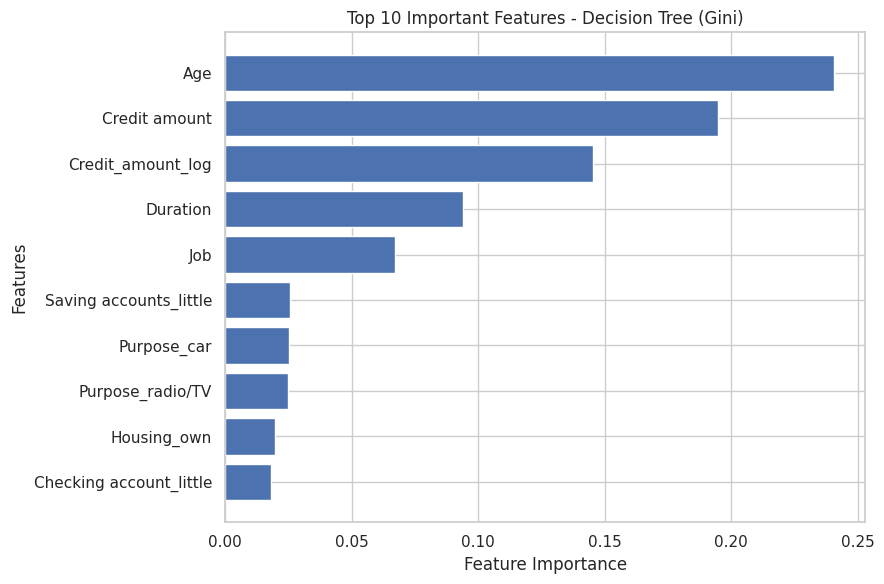

In [ ]:
# 7.1.1 Important Features in the Final Decision Tree

import pandas as pd
import matplotlib.pyplot as plt

# Use the Gini model with the 80/20 split
final_model = clf_80

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print("Top 10 Most Important Features:")
print(feature_importance.head(10).to_string(index=False))

# Plot the top 10 features
top_features = feature_importance.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features - Decision Tree (Gini)")
plt.tight_layout()
plt.show()

7.1.2 Model Evaluation

Accuracy, precision, recall, F1-score, and the confusion matrix are used to evaluate the model’s classification performance.

Final Model: Decision Tree (Gini, 80/20)
Test Accuracy: 0.66

Classification Report:
              precision    recall  f1-score   support

         bad       0.43      0.44      0.43        59
        good       0.76      0.75      0.76       141

    accuracy                           0.66       200
   macro avg       0.59      0.60      0.60       200
weighted avg       0.66      0.66      0.66       200



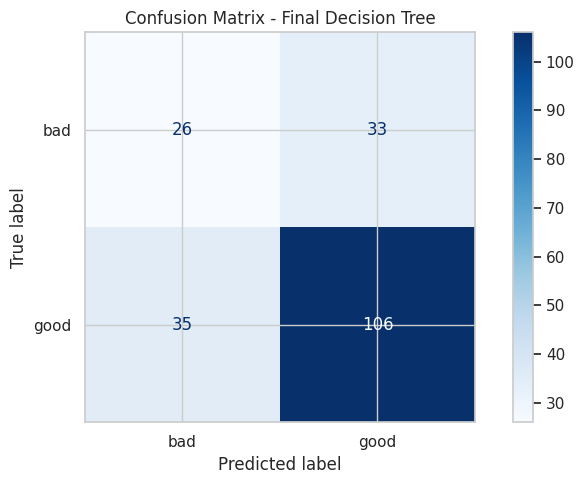

In [ ]:
# 7.1.2 Final Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

y_pred_final = final_model.predict(X_test_80)

print("Final Model: Decision Tree (Gini, 80/20)")
print("Test Accuracy:", round(
    accuracy_score(y_test_80, y_pred_final), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test_80,
    y_pred_final,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_80,
    y_pred_final,
    cmap="Blues"
)

plt.title("Confusion Matrix - Final Decision Tree")
plt.tight_layout()
plt.show()

7.1.3 Decision Tree Interpretation

The tree uses feature-based rules to classify customers into credit risk categories. Its decision rules help explain how predictions are made.

In [ ]:
# 7.1.3 Interpreting the Decision Tree Rules

from sklearn.tree import export_text

# Use the pruned tree already created for the 80/20 split
print("Decision Tree Rules (Gini, 80/20):")

tree_rules = export_text(
    clf_80_plot,
    feature_names=list(X.columns),
    max_depth=3
)

print(tree_rules)

Decision Tree Rules (Gini, 80/20):
|--- Duration <= 0.30
|   |--- Credit amount <= 0.97
|   |   |--- Age <= 0.32
|   |   |   |--- class: good
|   |   |--- Age >  0.32
|   |   |   |--- class: good
|   |--- Credit amount >  0.97
|   |   |--- class: bad
|--- Duration >  0.30
|   |--- Housing_own <= 0.50
|   |   |--- Purpose_business <= 0.50
|   |   |   |--- class: good
|   |   |--- Purpose_business >  0.50
|   |   |   |--- class: bad
|   |--- Housing_own >  0.50
|   |   |--- Saving accounts_little <= 0.50
|   |   |   |--- class: good
|   |   |--- Saving accounts_little >  0.50
|   |   |   |--- class: good



7.1.4 Overfitting Analysis

Comparing training and testing accuracy helps determine whether the model generalizes well to unseen data.

Training vs Testing Accuracy:
        Model  Tree depth  Training accuracy  Testing accuracy
Entropy 90/10          19                1.0            0.6000
Entropy 80/20          22                1.0            0.5850
Entropy 70/30          20                1.0            0.6367
   Gini 90/10          16                1.0            0.6400
   Gini 80/20          15                1.0            0.6600
   Gini 70/30          20                1.0            0.6233


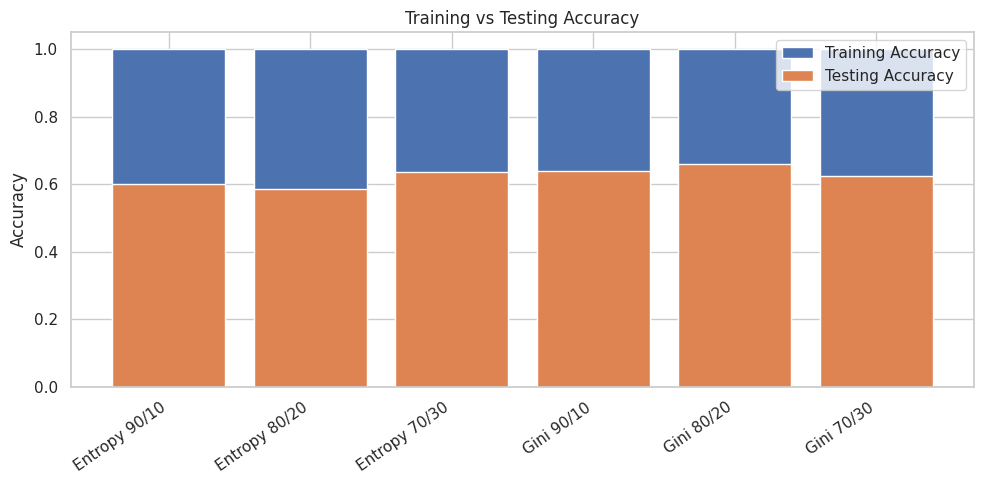

In [ ]:
# 7.1.4 Overfitting Analysis

print("Training vs Testing Accuracy:")
print(fit_check[
    ["Model", "Tree depth", "Training accuracy", "Testing accuracy"]
].round(4).to_string(index=False))

plt.figure(figsize=(10, 5))

plt.bar(
    fit_check["Model"],
    fit_check["Training accuracy"],
    label="Training Accuracy"
)

plt.bar(
    fit_check["Model"],
    fit_check["Testing accuracy"],
    label="Testing Accuracy"
)

plt.ylabel("Accuracy")
plt.title("Training vs Testing Accuracy")
plt.xticks(rotation=35, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

Overall Classification Findings

The Gini Decision Tree achieved the highest accuracy of 66% using the 80/20 data split. Age and Credit amount were the most important features in the model. The model performed better in identifying good-credit customers (recall = 0.75) than bad-credit customers (recall = 0.44). Furthermore, the 100% training accuracy compared with lower testing accuracy indicates potential overfitting. Overall, the model shows moderate classification performance and has limitations in identifying customers with bad credit.

## 7.2 Clustering Findings & Integration

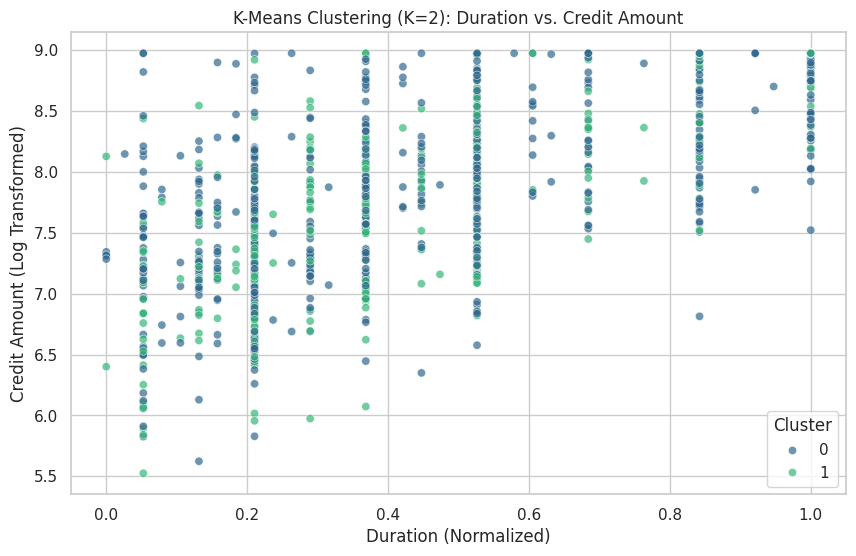

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Apply K-Means for K=2 and save results in a new column 'Cluster'
kmeans_best = KMeans(n_clusters=2, random_state=42, n_init=10)
df['Cluster'] = kmeans_best.fit_predict(X_scaled)

# Plot the clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=df['Duration'],
    y=df['Credit_amount_log'],
    hue=df['Cluster'],
    palette='viridis',
    alpha=0.7
)
plt.title("K-Means Clustering (K=2): Duration vs. Credit Amount")
plt.xlabel("Duration (Normalized)")
plt.ylabel("Credit Amount (Log Transformed)")
plt.show()

**Cluster Characteristics:**
By plotting the optimal clusters (K = 2) against the `Duration` and `Credit_amount_log` features, we can observe distinct customer segmentations based on financial behavior without relying on predefined risk labels:
*   **Cluster 0 (Low Financial Exposure):** This group primarily consists of applicants with shorter loan durations and smaller credit amounts. These characteristics typically represent a lower financial risk and a faster repayment cycle for the institution.
*   **Cluster 1 (High Financial Exposure):** This group captures applicants requesting significantly larger credit amounts over extended repayment periods. These instances represent higher financial exposure, align with the outliers identified during preprocessing, and require stricter credit evaluation.

**Overall Conclusion (Best Model):**
This project evaluated both classification (Decision Trees) and clustering (K-Means) techniques to assess credit risk.

While K-Means clustering successfully discovered underlying customer profiles—segmenting them into low and high exposure based on loan size and duration—it is an unsupervised technique. It identifies patterns but cannot directly assign a definitive "Good" or "Bad" risk label to a new applicant.

Therefore, the **Classification model** is the most actionable and effective technique for this specific business problem. Despite the challenges classification faces with imbalanced data (as it struggled to perfectly identify the minority class of "Bad" risk customers), it directly addresses the core objective: providing a clear predictive decision boundary. For a financial institution, a classification framework that directly outputs a risk prediction is practically more useful for approving or denying loans than exploratory clustering segmentation alone.

# **8-References**

[1] I. Aruleba and Y. Sun, "Effective Credit Risk Prediction Using Ensemble Classifiers With Model Explanation," IEEE Access, vol. 12, pp. 115015–115025, Aug. 2024. [Online]. Available: https://ieeexplore.ieee.org/abstract/document/10638034

[2] Kabure, "German Credit Data with Risk," Kaggle, 2018. [Online]. Available: https://www.kaggle.com/datasets/kabure/german-credit-data-with-risk